In [5]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
import os
import cv2 
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

read data

In [6]:
DATADIR = "archive/cell_images/cell_images" 
CATEGORIES = ["Uninfected", "Parasitized"]
IMG_SIZE = 64 
MAX_IMAGES_PER_CLASS = 7000

def extract_features(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    hist = cv2.calcHist([hsv], [0, 1, 2], None, [8, 8, 8], [0, 180, 0, 256, 0, 256])
    cv2.normalize(hist, hist)
    
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    means, stds = cv2.meanStdDev(rgb)
    
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    edge_var = [cv2.Laplacian(gray, cv2.CV_64F).var()]
    
    return np.hstack([hist.flatten(), means.flatten(), stds.flatten(), edge_var])

data = []

print("Extracting features from images... This might take a minute.")
for category in CATEGORIES:
    path = os.path.join(DATADIR, category)
    class_num = CATEGORIES.index(category) 
    
    count = 0
    if not os.path.isdir(path):
        print(f"Skipping missing folder: {path}")
        continue

    for img in os.listdir(path):
        if count >= MAX_IMAGES_PER_CLASS:
            break

        if not img.lower().endswith((".png", ".jpg", ".jpeg", ".bmp")):
            continue

        img_path = os.path.join(path, img)
        try:
            img_array = cv2.imread(img_path, cv2.IMREAD_COLOR)
            if img_array is not None:
                resized_img = cv2.resize(img_array, (IMG_SIZE, IMG_SIZE))
                features = extract_features(resized_img)
                data.append([features, class_num])
                count += 1
        except Exception:
            pass
        if count >= MAX_IMAGES_PER_CLASS:
            break
        try:
            img_array = cv2.imread(os.path.join(path, img), cv2.IMREAD_COLOR)
            if img_array is not None:
                resized_img = cv2.resize(img_array, (IMG_SIZE, IMG_SIZE))
                features = extract_features(resized_img)
                data.append([features, class_num])
                count += 1
        except Exception as e:
            pass


features_df = pd.DataFrame([item[0] for item in data])
features_df.columns = [f'feature_{i}' for i in range(features_df.shape[1])]
target_df = pd.DataFrame([item[1] for item in data], columns=['target'])
df = pd.concat([features_df, target_df], axis=1)

print(f"Data loading complete. Total samples: {len(df)}")
df.head()

Extracting features from images... This might take a minute.
Skipping missing folder: archive/cell_images/cell_images\Uninfected
Skipping missing folder: archive/cell_images/cell_images\Parasitized
Data loading complete. Total samples: 0


,target


analyze

In [7]:
df.info()

print(df['target'].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 0 entries
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   target  0 non-null      object
dtypes: object(1)
memory usage: 132.0+ bytes
Series([], Name: count, dtype: int64)


data preprocessing

In [8]:
df.isnull().sum()

target    0
dtype: int64

In [9]:
print("Missing values:\n", df.isnull().sum())

print("\nDuplicated Images:", df.duplicated().sum())

df.drop_duplicates(inplace=True)

df.head()

Missing values:
 target    0
dtype: int64

Duplicated Images: 0


,target


split data

feature and arget

In [10]:
x = df.drop(columns=['target'])
y = df['target']

split train test

In [15]:
if df.empty:
    raise ValueError(
        f"No image samples were loaded. Check DATADIR ({DATADIR!r}) and ensure "
        "it contains Uninfected and Parasitized folders with supported image files. "
        "Correct the path, then rerun the data-loading cell."
    )

x = df.drop(columns=["target"])
y = df["target"]

if len(df) < 2:
    raise ValueError("At least two image samples are required to split the data.")

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

print("x_train shape = ", x_train.shape)
print("y_train shape = ", y_train.shape)
print("x_test shape = ", x_test.shape)
print("y_test shape = ", y_test.shape)

ValueError: No image samples were loaded. Check DATADIR ('archive/cell_images/cell_images') and ensure it contains Uninfected and Parasitized folders with supported image files. Correct the path, then rerun the data-loading cell.

modeling before scalling

              precision    recall  f1-score   support

           0       0.74      0.76      0.75      1415
           1       0.75      0.72      0.74      1385

    accuracy                           0.74      2800
   macro avg       0.74      0.74      0.74      2800
weighted avg       0.74      0.74      0.74      2800



c:\Users\ENG_ISLAM\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


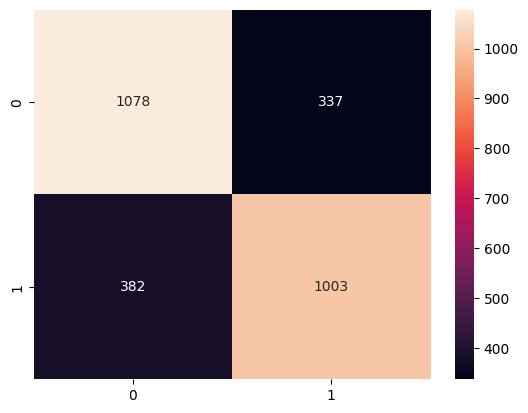

In [ ]:
log_model = LogisticRegression(max_iter=1000)
log_model.fit(x_train, y_train)

y_pred_log = log_model.predict(x_test)
print(classification_report(y_test, y_pred_log))

matrix = confusion_matrix(y_test, y_pred_log)
sns.heatmap(matrix, annot=True, fmt='d', cbar=True)
plt.show()

Best SVM:  SVC(C=0.1, kernel='linear')
              precision    recall  f1-score   support

           0       0.73      0.77      0.75      1415
           1       0.75      0.72      0.73      1385

    accuracy                           0.74      2800
   macro avg       0.74      0.74      0.74      2800
weighted avg       0.74      0.74      0.74      2800



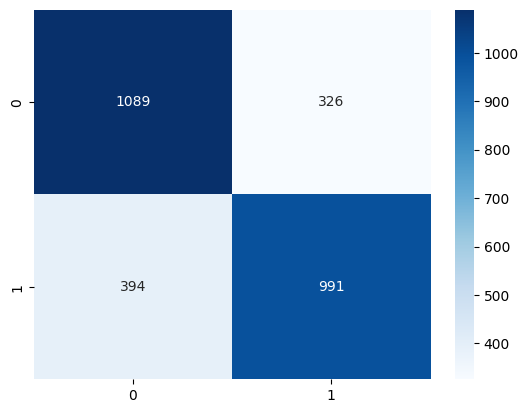

In [ ]:
svm_model = SVC()
params = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf'], 
}

grid_model = GridSearchCV(svm_model, params, n_jobs=-1, cv=3)
grid_model.fit(x_train, y_train)

print("Best SVM: ", grid_model.best_estimator_)
y_pred_grid = grid_model.predict(x_test)

print(classification_report(y_test, y_pred_grid))

matrix = confusion_matrix(y_test, y_pred_grid)
sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=True)
plt.show()

Best Tree:  DecisionTreeClassifier(max_depth=5)
              precision    recall  f1-score   support

           0       0.95      0.96      0.95      1415
           1       0.95      0.95      0.95      1385

    accuracy                           0.95      2800
   macro avg       0.95      0.95      0.95      2800
weighted avg       0.95      0.95      0.95      2800



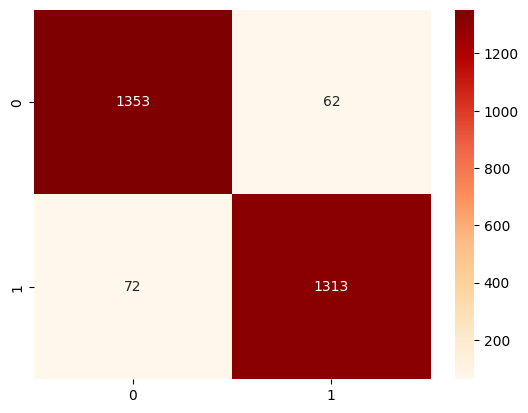

In [ ]:
tree1 = DecisionTreeClassifier()
params = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [5, 10, 15],
}

grid_tree_model = GridSearchCV(tree1, params, cv=3)
grid_tree_model.fit(x_train, y_train)

print("Best Tree: ", grid_tree_model.best_estimator_)
y_pred_tree1 = grid_tree_model.predict(x_test)

print(classification_report(y_test, y_pred_tree1))

matrix = confusion_matrix(y_test, y_pred_tree1)
sns.heatmap(matrix, annot=True, fmt='d', cmap='OrRd', cbar=True)
plt.show()



scalling data

In [ ]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=100, random_state=42)

x_train_pca = pca.fit_transform(x_train_scaled)

x_test_pca = pca.transform(x_test_scaled)

modeling after scalling

In [ ]:
log_model.fit(x_train_scaled, y_train)
y_pred_log_after = log_model.predict(x_test_scaled)

print(classification_report(y_test, y_pred_log_after))

matrix = confusion_matrix(y_test, y_pred_log_after)
sns.heatmap(matrix, annot=True, fmt='d', cbar=True)
plt.show()

NameError: name 'log_model' is not defined

              precision    recall  f1-score   support

           0       0.73      0.77      0.75      1415
           1       0.75      0.72      0.73      1385

    accuracy                           0.74      2800
   macro avg       0.74      0.74      0.74      2800
weighted avg       0.74      0.74      0.74      2800



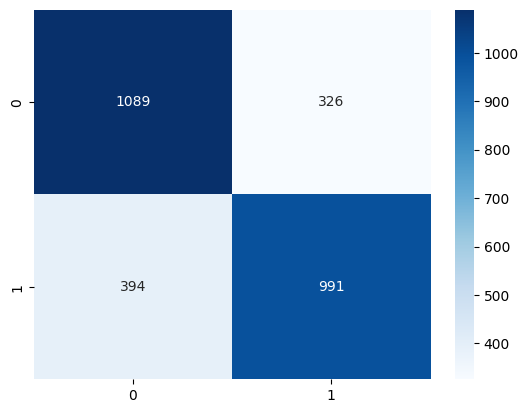

In [ ]:
grid_model.fit(x_train, y_train)
y_pred_grid_after = grid_model.predict(x_test)

print(classification_report(y_test, y_pred_grid_after))

matrix = confusion_matrix(y_test, y_pred_grid_after)
sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=True)
plt.show()

              precision    recall  f1-score   support

           0       0.95      0.96      0.95      1415
           1       0.95      0.95      0.95      1385

    accuracy                           0.95      2800
   macro avg       0.95      0.95      0.95      2800
weighted avg       0.95      0.95      0.95      2800



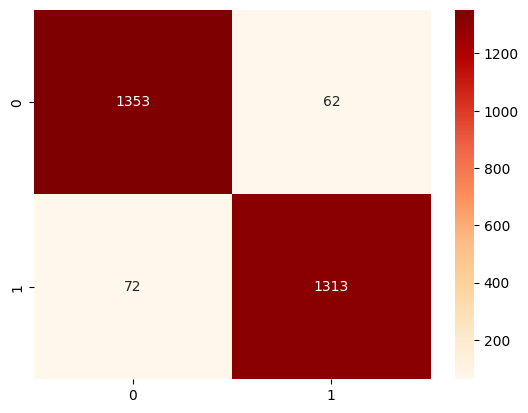

In [ ]:
grid_tree_model.fit(x_train, y_train)
y_pred_tree1_after = grid_tree_model.predict(x_test)

print(classification_report(y_test, y_pred_tree1_after))

matrix = confusion_matrix(y_test, y_pred_tree1_after)
sns.heatmap(matrix, annot=True, fmt='d', cmap='OrRd', cbar=True)
plt.show()

In [ ]:
from joblib import dump

if not os.path.exists('Models'):
    os.makedirs('Models')

dump(log_model, 'Models/logistic_model_cells.joblib')
dump(grid_model, 'Models/svm_model_cells.joblib')
dump(grid_tree_model, 'Models/tree_model_cells.joblib')
dump(scaler, 'Models/scaler_cells.joblib')

['Models/scaler_cells.joblib']